<a href="https://colab.research.google.com/github/Nakyejjwe/Data-Science-Portfolio/blob/main/Assignment1_Nakyejjwe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Automobile Data Analysis
This notebook demonstrates how to load, clean, and analyze automobile specification data to understand the factors influencing car prices.

In [29]:
# Bringing in the tools that read the tables

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

In [30]:
# We use a web address (URL) to fetch our dataset directly from the internet since it is absent in our local directory.
# This is super helpful because it loads the data automatically every time, even if we restart our notebook!
url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv'
df = pd.read_csv(url)

# It displays the first 5 cars in the table
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [31]:
# counting the missing values we have in each column
missing_counts = df.isnull().sum()

# Filtering to only show columns that have at least 1 missing value
columns_with_missing_values = missing_counts[missing_counts > 0]

print("--- Columns with Missing Values ---")
if len(columns_with_missing_values) > 0:
    print(columns_with_missing_values)
else:
    print("Hooray! No missing values found in any column!")

# Checking for any matching duplicate rows
total_duplicates = df.duplicated().sum()
print(f"\nTotal duplicate rows found: {total_duplicates}")

--- Columns with Missing Values ---
stroke               4
horsepower-binned    1
dtype: int64

Total duplicate rows found: 0


In [32]:
# Calculate the average (mean) of the 'stroke' column
stroke_average = df['stroke'].mean()

# Fill the missing spaces in 'stroke' with that average
df['stroke'].fillna(stroke_average, inplace=True)

# Find the most common category in 'horsepower-binned'
most_common_hp = df['horsepower-binned'].mode()[0]

# Fill the missing space in 'horsepower-binned' with that category
df['horsepower-binned'].fillna(most_common_hp, inplace=True)

# Checking again if we have any missing values left!
print("Missing values left:")
print(df.isnull().sum().sum())

Missing values left:
0


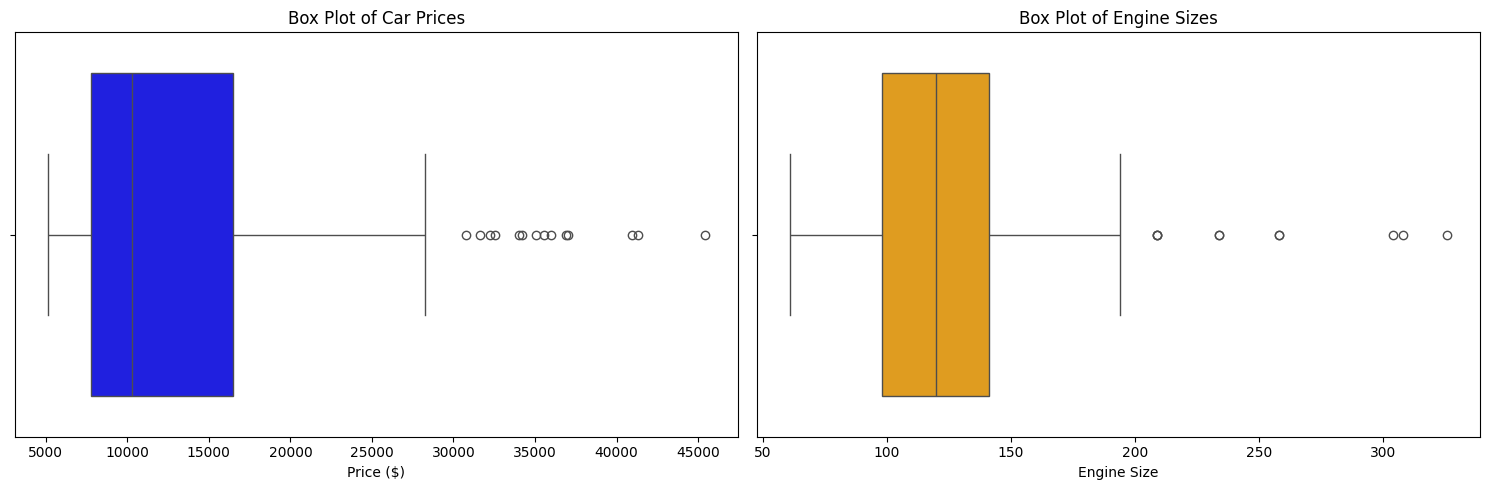

In [33]:
# Drawing box plots for price and engine-size to look for extreme outliers

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot for Price

sns.boxplot(ax=axes[0], x=df['price'], color='blue')
axes[0].set_title('Box Plot of Car Prices')
axes[0].set_xlabel('Price ($)')

# Boxplot for Engine Size

sns.boxplot(ax=axes[1], x=df['engine-size'], color='orange')
axes[1].set_title('Box Plot of Engine Sizes')
axes[1].set_xlabel('Engine Size')

plt.tight_layout()
plt.show()

In [34]:
# Since we found no missing values or duplicates, we save our cleaned dataset!

your_last_name = "Nakyejjwe"
df.to_csv(f"{your_last_name}_Data.csv", index=False)
print(f"Success! cleaned file saved")

Success! cleaned file saved


In [35]:
# Summary statistics for continuous variables

continuous_summary = df.describe()
print("   Summary Statistics for Continuous Variables   ")
print(continuous_summary)

   Summary Statistics for Continuous Variables   
        symboling  normalized-losses  wheel-base      length       width  \
count  201.000000          201.00000  201.000000  201.000000  201.000000   
mean     0.840796          122.00000   98.797015    0.837102    0.915126   
std      1.254802           31.99625    6.066366    0.059213    0.029187   
min     -2.000000           65.00000   86.600000    0.678039    0.837500   
25%      0.000000          101.00000   94.500000    0.801538    0.890278   
50%      1.000000          122.00000   97.000000    0.832292    0.909722   
75%      2.000000          137.00000  102.400000    0.881788    0.925000   
max      3.000000          256.00000  120.900000    1.000000    1.000000   

           height  curb-weight  engine-size        bore      stroke  \
count  201.000000   201.000000   201.000000  201.000000  201.000000   
mean    53.766667  2555.666667   126.875622    3.330692    3.256904   
std      2.447822   517.296727    41.546834    0.268

In [36]:
 # Frequency counts for categorical variables

categorical_cols = df.select_dtypes(include=['object']).columns

print("--- Frequency Counts for Categorical Variables ---")
for col in categorical_cols:
    print(f"\nFrequency Counts for '{col}':")
    print(df[col].value_counts())
    print("-" * 40)

--- Frequency Counts for Categorical Variables ---

Frequency Counts for 'make':
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
chevrolet         3
alfa-romero       3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64
----------------------------------------

Frequency Counts for 'aspiration':
aspiration
std      165
turbo     36
Name: count, dtype: int64
----------------------------------------

Frequency Counts for 'num-of-doors':
num-of-doors
four    115
two      86
Name: count, dtype: int64
----------------------------------------

Frequency Counts for 'body-style':
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
conver

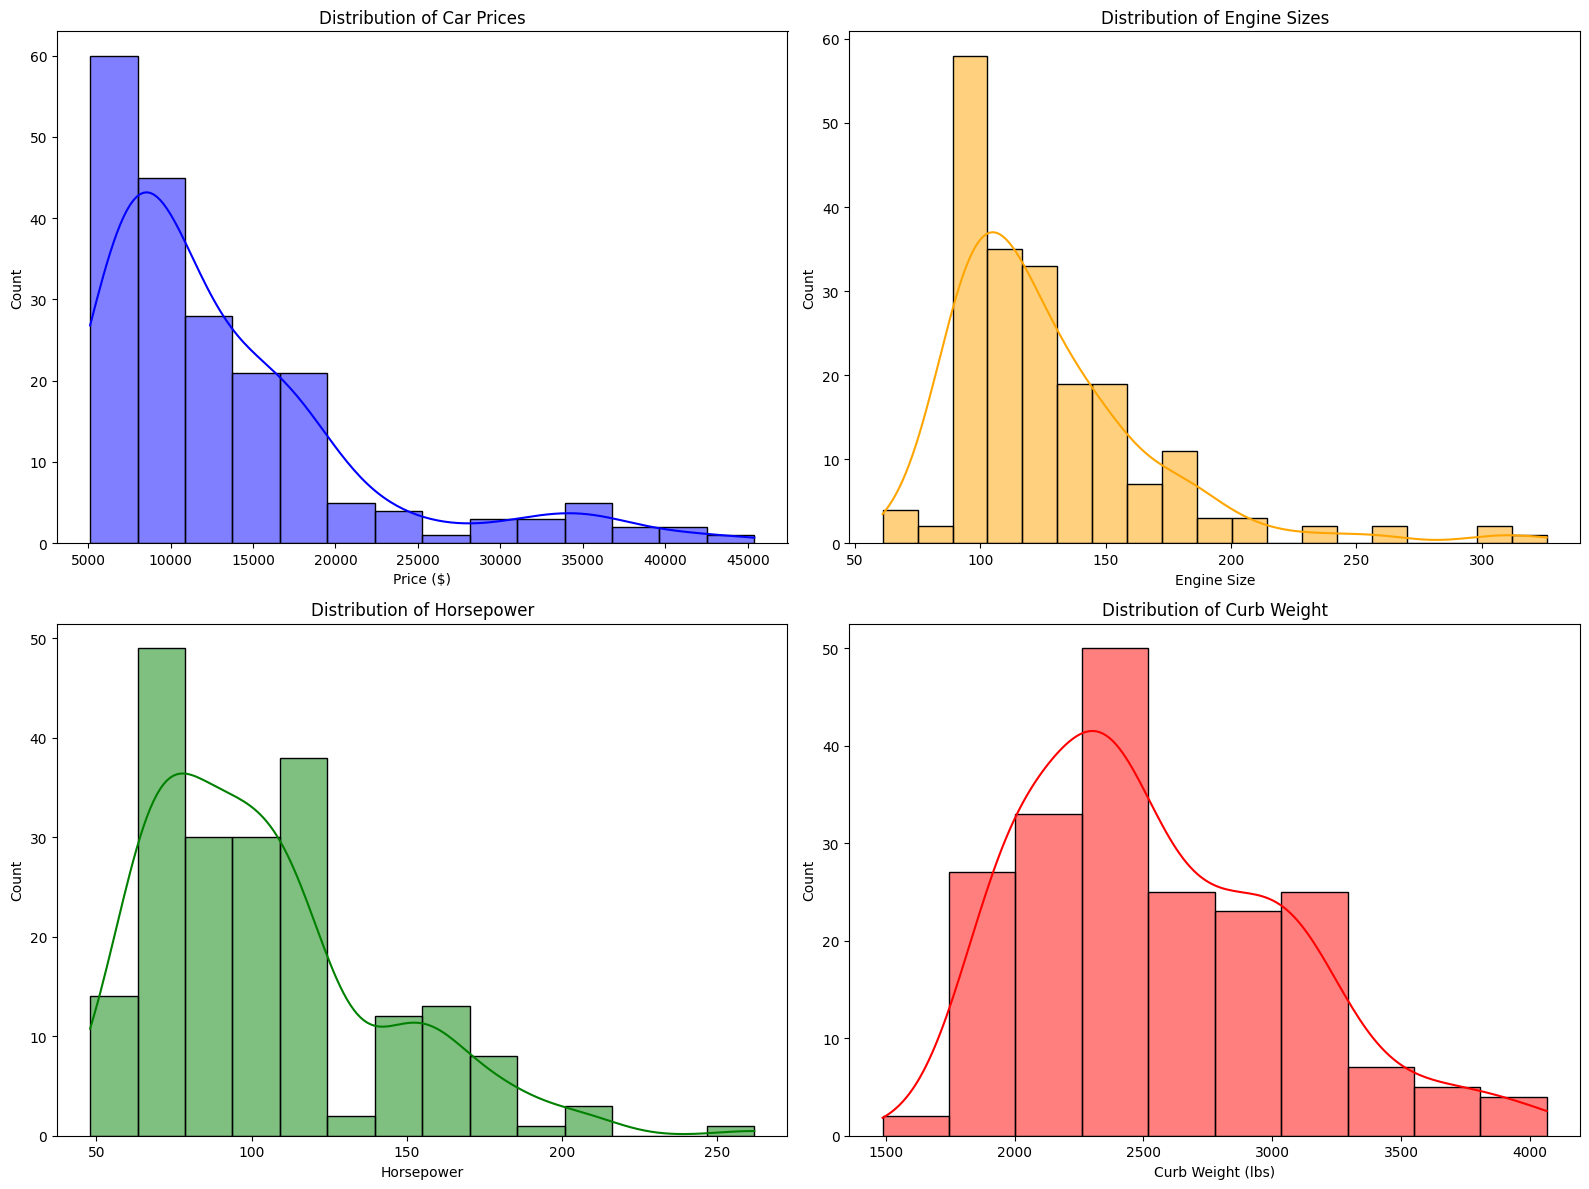

In [37]:
# Visualizing distributions of Price and key metrics
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Price Distribution
sns.histplot(df['price'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Distribution of Car Prices')
axes[0, 0].set_xlabel('Price ($)')

# Engine Size Distribution
sns.histplot(df['engine-size'], kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Distribution of Engine Sizes')
axes[0, 1].set_xlabel('Engine Size')

# Horsepower Distribution
sns.histplot(df['horsepower'], kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title('Distribution of Horsepower')
axes[1, 0].set_xlabel('Horsepower')

# Curb Weight Distribution
sns.histplot(df['curb-weight'], kde=True, ax=axes[1, 1], color='red')
axes[1, 1].set_title('Distribution of Curb Weight')
axes[1, 1].set_xlabel('Curb Weight (lbs)')

plt.tight_layout()
plt.show()

Summary of the Patterns Observed

Price Distribution: The car prices are strongly right-skewed where most cars are priced under $15,000, with a few high-end luxury/sports cars stretching the scale past $30,000.

Engine Specs: Features like engine size and horsepower also exhibit a right-skewed distribution, matching the pattern seen in prices.

Market Composition: The frequency counts reveal that the market is heavily dominated by gas-fueled, front-engine, front-wheel-drive sedan and hatchback models.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [38]:

# Grouping data by 'drive-wheels' and 'body-style' and finding the mean price
grouped_df = df[['drive-wheels', 'body-style', 'price']].groupby(['drive-wheels', 'body-style'], as_index=False).mean()

# Creating a pivot table for cleaner representation and easier visualization
grouped_pivot = grouped_df.pivot(index='drive-wheels', columns='body-style', values='price')

# Fill missing values with 0 for visualization completeness if any group doesn't exist
grouped_pivot = grouped_pivot.fillna(0)

print("Average Price Table by Drive Wheels and Body Style")
print(grouped_pivot)

Average Price Table by Drive Wheels and Body Style
body-style    convertible       hardtop     hatchback         sedan  \
drive-wheels                                                          
4wd                   0.0      0.000000   7603.000000  12647.333333   
fwd               11595.0   8249.000000   8396.387755   9811.800000   
rwd               23949.6  24202.714286  14337.777778  21711.833333   

body-style           wagon  
drive-wheels                
4wd            9095.750000  
fwd            9997.333333  
rwd           16994.222222  


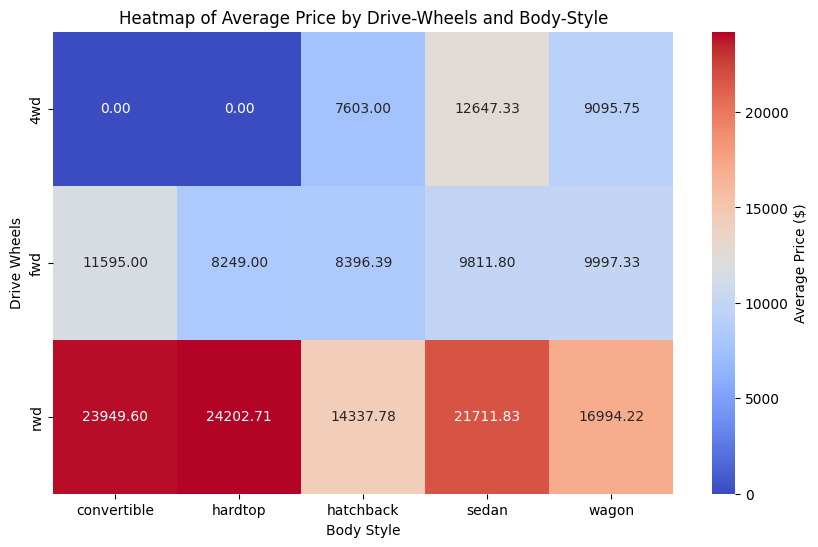

In [39]:
# Plotting a heatmap to visually interpret the prices across groups

plt.figure(figsize=(10, 6))
sns.heatmap(grouped_pivot, annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={'label': 'Average Price ($)'})
plt.title('Heatmap of Average Price by Drive-Wheels and Body-Style')
plt.xlabel('Body Style')
plt.ylabel('Drive Wheels')
plt.show()

In [40]:
# Identifying the highest and lowest priced groups
# Finding the non-zero minimum and maximum in the grouped dataframe

valid_groups = grouped_df.dropna()

highest_group = valid_groups.loc[valid_groups['price'].idxmax()]
lowest_group = valid_groups.loc[valid_groups['price'].idxmin()]

print(f"Highest Average Price Group: {highest_group['drive-wheels']} + {highest_group['body-style']} (${highest_group['price']:.2f})")
print(f"Lowest Average Price Group: {lowest_group['drive-wheels']} + {lowest_group['body-style']} (${lowest_group['price']:.2f})")

Highest Average Price Group: rwd + hardtop ($24202.71)
Lowest Average Price Group: 4wd + hatchback ($7603.00)


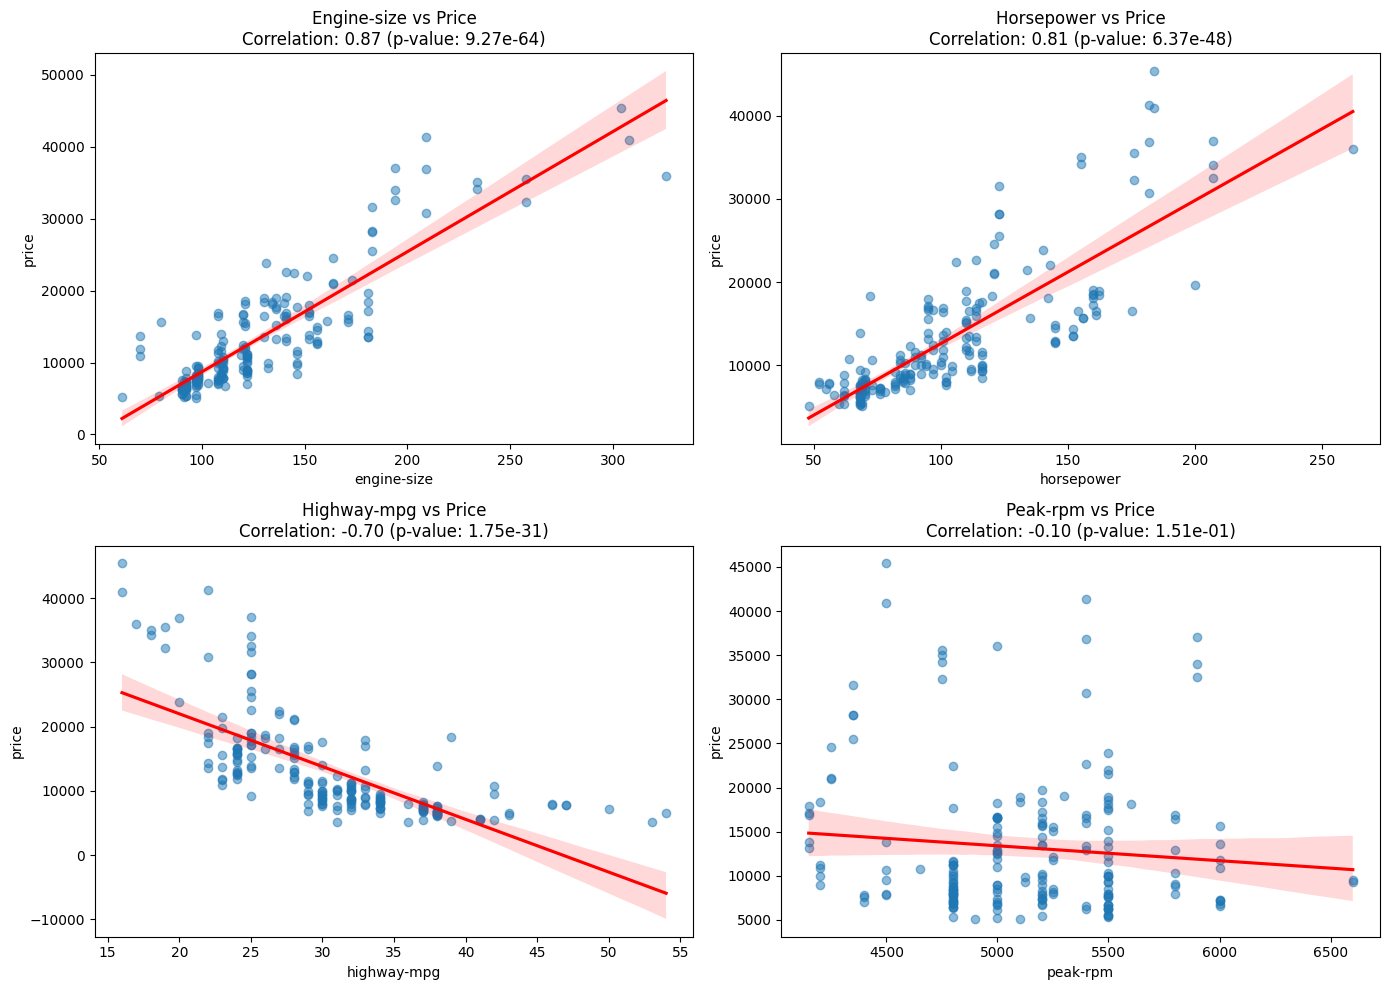

In [41]:
import scipy.stats as stats

continuous_vars = ['engine-size', 'horsepower', 'highway-mpg', 'peak-rpm']

# Create scatter plots with regression lines
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, var in enumerate(continuous_vars):
    sns.regplot(x=var, y='price', data=df, ax=axes[i], scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
# Calculate Pearson Correlation
    pearson_coef, p_value = stats.pearsonr(df[var], df['price'])
    axes[i].set_title(f"{var.capitalize()} vs Price\nCorrelation: {pearson_coef:.2f} (p-value: {p_value:.2e})")

plt.tight_layout()
plt.show()

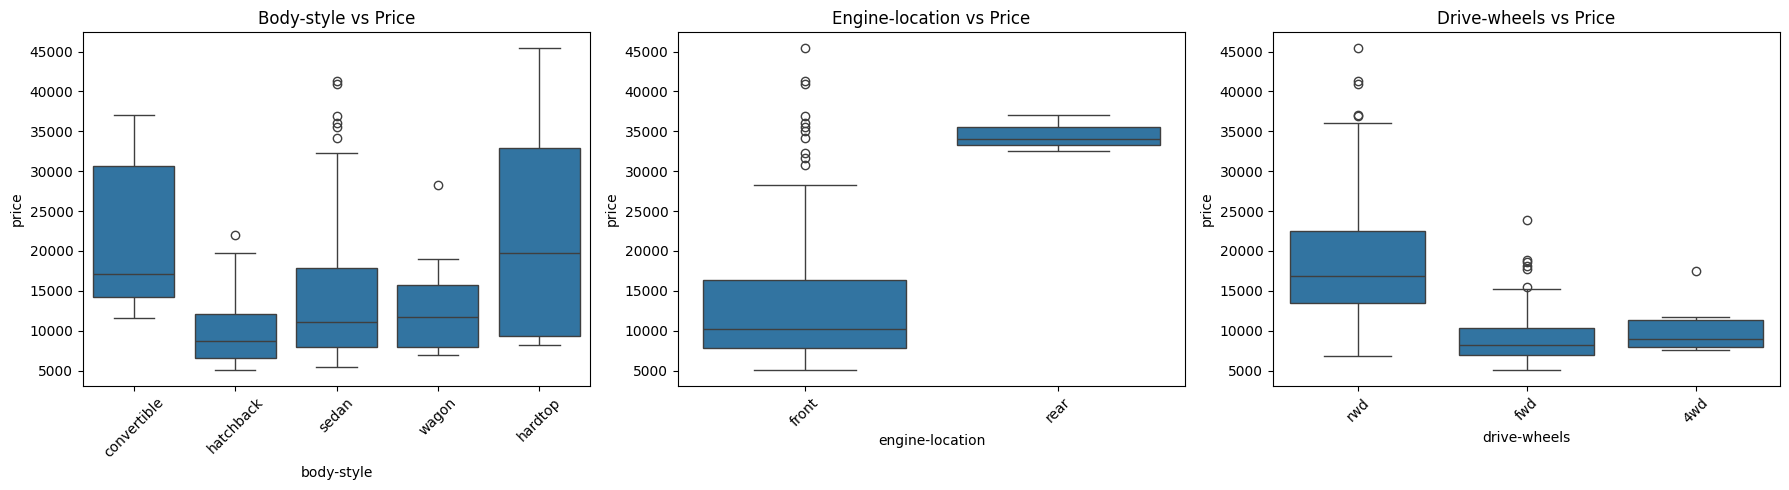

In [42]:
categorical_vars = ['body-style', 'engine-location', 'drive-wheels']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, var in enumerate(categorical_vars):
    sns.boxplot(x=var, y='price', data=df, ax=axes[i])
    axes[i].set_title(f'{var.capitalize()} vs Price')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Summary Statistics for Price by Engine Location and Aspiration
  engine-location aspiration          mean  count          std
0           front        std  12135.037037    162  7640.927108
1           front      turbo  16254.805556     36  6179.615923
2            rear        std  34528.000000      3  2291.287847


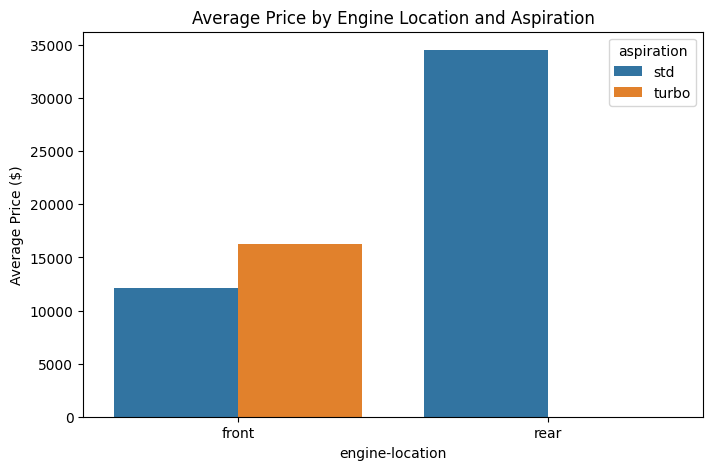

In [43]:
double_categoricals = df.groupby(['engine-location', 'aspiration'])['price'].agg(['mean', 'count', 'std']).reset_index()
print("Summary Statistics for Price by Engine Location and Aspiration")
print(double_categoricals)

# Visualizing the interaction
plt.figure(figsize=(8, 5))
sns.barplot(x='engine-location', y='price', hue='aspiration', data=df, errorbar=None)
plt.title('Average Price by Engine Location and Aspiration')
plt.ylabel('Average Price ($)')
plt.show()

In [44]:
# Isolate the numerical variables for analysis
numeric_cols = df.select_dtypes(include=[np.number])

# Split into independent attributes (X) and target variable (y)
X = numeric_cols.drop(columns=['price'])
y = numeric_cols['price']

# Fit the SelectKBest selector using F-Regression
selector = SelectKBest(score_func=f_regression, k='all')
selector.fit(X, y)

# Compile the feature scores into a formatted table
feature_rankings = pd.DataFrame({
    'Feature': X.columns,
    'F-Score': selector.scores_,
    'p-value': selector.pvalues_
}).sort_values(by='F-Score', ascending=False)

print("Top Numerical Features Affecting Price")
print(feature_rankings)

Top Numerical Features Affecting Price
              Feature     F-Score       p-value
7         engine-size  633.526760  9.265492e-64
6         curb-weight  456.138858  2.189577e-53
11         horsepower  378.499538  6.369057e-48
15       city-L/100km  330.168178  3.903106e-44
4               width  257.840737  9.200336e-38
14        highway-mpg  196.304960  1.749547e-31
3              length  181.473532  8.016477e-30
13           city-mpg  177.451714  2.321132e-29
2          wheel-base  103.342498  8.076488e-20
8                bore   83.276619  8.049189e-17
5              height    3.721261  5.514627e-02
1   normalized-losses    3.638508  5.789749e-02
17                gas    2.452020  1.189625e-01
16             diesel    2.452020  1.189625e-01
12           peak-rpm    2.076271  1.511769e-01
0           symboling    1.360106  2.449149e-01
9              stroke    1.355984  2.456287e-01
10  compression-ratio    1.011308  3.158110e-01


These are the core recommendations for a car dealer setting vehicle prices:

Prioritize Engine Performance (engine-size and horsepower): These two attributes scored the highest statistical relationship with price. A dealer should set a premium pricing tier for vehicles with larger displacement sizes and high horsepower specs.

Leverage Structural Weights and Dimensions (curb-weight and width): Heavier and wider premium vehicles are highly correlated with increased costs. Standardizing a markup for larger structural classes (SUVs/Luxury Sedans) is highly justified by historical market trends.

Optimally Balance Fuel Efficiency: City and highway fuel economy indicators demonstrate a high inverse (negative) correlation with price. High-tier premium sports or heavy utility models command high prices despite having lower MPG figures.